In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 85.6 MB/s eta 0:00:00


In [3]:
import shutil

files = ['fast_kan_conv.py', 'kan_conv.py', 'kan.py', 'layers.py', 'utils.py', '__init__.py']

for f in files:

    shutil.copy(f'/content/drive/MyDrive/GKANSU/{f}', f'/content/{f}')

print("All files copied successfully!")

All files copied successfully!


In [4]:
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch_geometric.nn as pyg_nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torch_geometric.data import Data, DataLoader as GeometricDataLoader
from skimage.metrics import mean_squared_error
from fast_kan_conv import FastKANConv2DLayer
from kan_conv import KANConv2DLayer

# Spatial-Spectral Attention Module
class SpatialSpectralAttention(nn.Module):
    def __init__(self, channels):
        super(SpatialSpectralAttention, self).__init__()
        self.conv1x1 = nn.Conv2d(channels, channels // 2, kernel_size=1)
        self.conv3x3 = nn.Conv2d(channels // 2, channels, kernel_size=3, padding=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attn = self.conv1x1(x)
        attn = self.conv3x3(attn)
        attn = self.sigmoid(attn)
        return x * attn

# Improved Graph-KAN Spectral Upsampling Model with Residual Projection
class GKANSU_Improved(nn.Module):
    def __init__(self, in_channels, out_channels, hidden_dim=128, num_gat_layers=3, img_size=(64, 64)):
        """
        :param in_channels: Number of input spectral bands (e.g., 20)
        :param out_channels: Number of output spectral bands (e.g., 200)
        :param hidden_dim: Hidden dimension for the GAT/KAN layers
        :param num_gat_layers: Number of GAT layers to stack
        :param img_size: (height, width) of each image patch
        """
        super(GKANSU_Improved, self).__init__()
        self.img_size = img_size

        # Add a projection layer to match input channels to hidden_dim
        if in_channels != hidden_dim:
            self.input_proj = nn.Linear(in_channels, hidden_dim)
        else:
            self.input_proj = nn.Identity()

        # Graph-Spectral Feature Extraction using multiple GAT layers
        self.gat_layers = nn.ModuleList()
        self.batch_norms = nn.ModuleList()

        # First GAT layer
        self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
        self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Additional GAT layers
        for _ in range(num_gat_layers - 1):
            self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
            self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Multiple KAN Blocks with Residual Connections
        self.fast_kan1 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)
        self.fast_kan2 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)

        # Spatial-Spectral Attention
        self.ssa = SpatialSpectralAttention(hidden_dim)

        # Final KAN-based Refinement
        self.final_refinement = KANConv2DLayer(hidden_dim, out_channels, kernel_size=3, padding=1)

        # Non-negativity constraint (using ReLU only)
        self.relu = nn.ReLU()

    def forward(self, x, edge_index):
        """
        :param x: Node features, shape [num_nodes, in_channels]
        :param edge_index: Graph edges (2, E)
        :return: Super-resolved output, shape [batch, out_channels, H, W]
        """
        # Project input features to hidden_dim
        x = self.input_proj(x)

        # Graph-Spectral Learning with GAT layers with skip connections
        for gat_layer, bn in zip(self.gat_layers, self.batch_norms):
            residual = x
            x = gat_layer(x, edge_index)
            x = bn(x)
            x = F.relu(x + residual)

        # Reshape from (num_nodes, hidden_dim) to (batch, hidden_dim, H, W)
        num_nodes = x.shape[0]
        batch_size = num_nodes // (self.img_size[0] * self.img_size[1])
        x = x.view(batch_size, self.img_size[0], self.img_size[1], -1)
        x = x.permute(0, 3, 1, 2)

        # Multiple KAN Blocks with skip connections
        residual = x
        x = self.fast_kan1(x)
        x = F.relu(x + residual)

        residual = x
        x = self.fast_kan2(x)
        x = F.relu(x + residual)

        # Spatial-Spectral Attention
        x = self.ssa(x)

        # Final KAN-based Refinement
        x = self.final_refinement(x)

        # Apply non-negativity constraint
        x = self.relu(x)

        return x



# Data Prep

In [11]:
# Data PRep
# Data Loading Function
def load_npy_files_from_folder(folder_path):
    npy_files = [f for f in os.listdir(folder_path) if f.endswith('.npy')]
    npy_files.sort()
    arrays = [np.load(os.path.join(folder_path, file)) for file in npy_files]
    return np.stack(arrays, axis=0)

# Paths to LR and HR Data
LR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/low_res_patches'
HR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/high_res_patches'
lr_images = load_npy_files_from_folder(LR_folder_path).astype(np.float32)
hr_images = load_npy_files_from_folder(HR_folder_path).astype(np.float32)

# ----------- NORMALIZATION -----------
# Min-Max Normalization per channel
lr_min = lr_images.min(axis=(0, 1, 2), keepdims=True)
lr_max = lr_images.max(axis=(0, 1, 2), keepdims=True)
hr_min = hr_images.min(axis=(0, 1, 2), keepdims=True)
hr_max = hr_images.max(axis=(0, 1, 2), keepdims=True)
"""
lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)
"""

lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)


# ── ADD AUGMENTATION HERE ──────────────────────────────────────
def augment_hsi(lr, hr):
    augmented_lr, augmented_hr = [lr], [hr]
    augmented_lr.append(np.flip(lr, axis=1).copy())
    augmented_hr.append(np.flip(hr, axis=1).copy())
    augmented_lr.append(np.flip(lr, axis=0).copy())
    augmented_hr.append(np.flip(hr, axis=0).copy())
    augmented_lr.append(np.rot90(lr, k=1).copy())
    augmented_hr.append(np.rot90(hr, k=1).copy())
    augmented_lr.append(np.rot90(lr, k=2).copy())
    augmented_hr.append(np.rot90(hr, k=2).copy())
    return augmented_lr, augmented_hr

aug_lr, aug_hr = [], []
for lr, hr in zip(lr_images, hr_images):
    lrs, hrs = augment_hsi(lr, hr)
    aug_lr.extend(lrs)
    aug_hr.extend(hrs)

lr_images = np.array(aug_lr)
hr_images = np.array(aug_hr)
print(f"After augmentation: {len(lr_images)} samples")  # should print 140
# ──────────────────────────────────────────────────────────────

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)



# Function to Create Graph Data
def create_graph_from_image(image):
    H, W, C = image.shape
    num_nodes = H * W
    features = image.reshape(num_nodes, C)  # Flatten spatial dims

    edge_index = []
    for i in range(H):
        for j in range(W):
            node = i * W + j
            if i > 0: edge_index.append([node, node - W])
            if i < H - 1: edge_index.append([node, node + W])
            if j > 0: edge_index.append([node, node - 1])
            if j < W - 1: edge_index.append([node, node + 1])
    edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()

    return Data(x=torch.tensor(features, dtype=torch.float), edge_index=edge_index)

# Graph Dataset Class
class HSI_GraphDataset(Dataset):
    def __init__(self, lr_images, hr_images):
        assert len(lr_images) == len(hr_images), "LR and HR images must have the same number of samples"
        self.graphs = [create_graph_from_image(img) for img in lr_images]
        self.hr_images = [torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) for img in hr_images]

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        return self.graphs[idx], self.hr_images[idx]


After augmentation: 180 samples


In [10]:
import torch
print(torch.cuda.is_available())        # Should print True
print(torch.cuda.get_device_name(0))    # Should print T4 or similar

print(torch.cuda.get_device_name(0))  # run this before training

True
Tesla T4
Tesla T4


# Training

/tmp/ipykernel_489/909018205.py:4: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
/tmp/ipykernel_489/909018205.py:5: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=False)


Epoch 1/150, SAM+MSE Loss: 0.6535
Epoch 2/150, SAM+MSE Loss: 0.4763
Epoch 3/150, SAM+MSE Loss: 0.3862
Epoch 4/150, SAM+MSE Loss: 0.3242
Epoch 5/150, SAM+MSE Loss: 0.2741
Epoch 6/150, SAM+MSE Loss: 0.2406
Epoch 7/150, SAM+MSE Loss: 0.2233
Epoch 8/150, SAM+MSE Loss: 0.2132
Epoch 9/150, SAM+MSE Loss: 0.2025
Epoch 10/150, SAM+MSE Loss: 0.1969
Epoch 11/150, SAM+MSE Loss: 0.1988
Early stopping trigger count: 1/10
Epoch 12/150, SAM+MSE Loss: 0.1930
Epoch 13/150, SAM+MSE Loss: 0.1818
Epoch 14/150, SAM+MSE Loss: 0.1778
Epoch 15/150, SAM+MSE Loss: 0.1778
Early stopping trigger count: 1/10
Epoch 16/150, SAM+MSE Loss: 0.1724
Epoch 17/150, SAM+MSE Loss: 0.1717
Epoch 18/150, SAM+MSE Loss: 0.1681
Epoch 19/150, SAM+MSE Loss: 0.1625
Epoch 20/150, SAM+MSE Loss: 0.1618
Epoch 21/150, SAM+MSE Loss: 0.1609
Epoch 22/150, SAM+MSE Loss: 0.1564
Epoch 23/150, SAM+MSE Loss: 0.1537
Epoch 24/150, SAM+MSE Loss: 0.1559
Early stopping trigger count: 1/10
Epoch 25/150, SAM+MSE Loss: 0.1534
Epoch 26/150, SAM+MSE Loss: 0

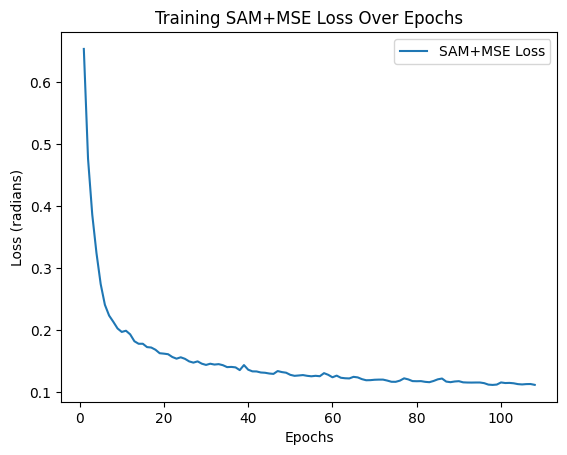

In [12]:
# Data Loaders
train_dataset = HSI_GraphDataset(trainSL, trainSH)
test_dataset = HSI_GraphDataset(testSL, testSH)
train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=False)
# Training for 150 epochs
'''
# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

#epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()

'''

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Custom SAM Loss Function
def sam_loss(hr, sr, eps=1e-8):
    """
    Compute the Spectral Angle Mapper (SAM) loss between two images.
    hr and sr should be tensors of shape [batch, channels, H, W].
    Returns the average spectral angle (in radians) over all pixels.
    """
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)
    dot_product = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)
    cos_angle = dot_product / (hr_norm * sr_norm + eps)
    cos_angle = torch.clamp(cos_angle, -1.0, 1.0)
    angle = torch.acos(cos_angle)
    return torch.mean(angle)

# Combined SAM + MSE Loss
def combined_loss(hr, sr, alpha=0.7, eps=1e-8):
    sam  = sam_loss(hr, sr, eps)
    mse  = F.mse_loss(sr, hr)
    return alpha * sam + (1 - alpha) * mse

# Model Training with Early Stopping and SAM+MSE Loss
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
# Use combined SAM + MSE loss instead of SAM only
criterion = combined_loss

loss_history = []
patience = 10
min_delta = 1e-4
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, SAM+MSE Loss: {avg_loss:.4f}")

    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="SAM+MSE Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (radians)")
plt.title("Training SAM+MSE Loss Over Epochs")
plt.legend()
plt.show()

In [13]:
# ============================================================
# KAN-KO PRUNING — GKANSU
# Full metric tracking: RMSE, SAM (Method 1: pixel-wise arccos),
# SAM (Method 2: batch mean via sam_loss_fn), PSNR, SSIM
# Three stages: Baseline → After Prune → After Finetune
# ============================================================

import torch
import numpy as np
import copy
from skimage.metrics import structural_similarity as ssim

# ── SAM Method 1: pixel-wise arccos (your original spectral_angle_mapper) ──
def sam_pixelwise(img_sr, img_hr):
    """
    Compute SAM pixel-by-pixel then average.
    img_sr, img_hr: numpy arrays (H, W, C)
    This is the same as your spectral_angle_mapper() function.
    """
    flat_s = img_sr.reshape(-1, img_sr.shape[-1])
    flat_h = img_hr.reshape(-1, img_hr.shape[-1])
    norm_s = np.linalg.norm(flat_s, axis=1, keepdims=True)
    norm_h = np.linalg.norm(flat_h, axis=1, keepdims=True)
    dot    = np.sum(flat_s * flat_h, axis=1, keepdims=True)
    cosine = np.clip(dot / (norm_s * norm_h + 1e-8), -1.0, 1.0)
    angles = np.arccos(cosine)
    return float(np.mean(angles))

# ── SAM Method 2: batch cosine via sam_loss_fn (your training loss) ──
def sam_batchwise(sr_tensor, hr_tensor, eps=1e-8):
    """
    Compute SAM the same way sam_loss_fn does (torch, batch cosine).
    sr_tensor, hr_tensor: torch tensors (B, C, H, W)
    Returns scalar float.
    """
    batch, channels, H, W = hr_tensor.shape
    hr_flat = hr_tensor.view(batch, channels, -1)
    sr_flat = sr_tensor.view(batch, channels, -1)
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)
    dot     = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)
    cos_a   = torch.clamp(dot / (hr_norm * sr_norm + eps), -1.0, 1.0)
    return torch.mean(torch.acos(cos_a)).item()

# ── Full metrics: all 4 metrics + both SAM methods ────────────
def evaluate_all_metrics(model, test_loader, device):
    """
    Returns dict with:
      RMSE, SAM_M1 (pixel-wise), SAM_M2 (batchwise), PSNR, SSIM
    """
    model.eval()
    rmse_vals  = []
    sam_m1_vals = []   # Method 1: pixel-wise arccos (numpy)
    sam_m2_vals = []   # Method 2: batch cosine (torch, same as loss)
    psnr_vals  = []
    ssim_vals  = []

    with torch.no_grad():
        for graph_data, hr_imgs in test_loader:
            graph_data = graph_data.to(device)
            hr_imgs    = hr_imgs.to(device).float()
            sr = model(graph_data.x, graph_data.edge_index)
            sr = sr.view(hr_imgs.shape)

            # SAM Method 2 on full batch tensor (before going to numpy)
            sam_m2_vals.append(sam_batchwise(sr, hr_imgs))

            sr_np = sr.cpu().numpy()
            hr_np = hr_imgs.cpu().numpy()

            for b in range(sr_np.shape[0]):
                s = sr_np[b].transpose(1, 2, 0)   # (H, W, C)
                h = hr_np[b].transpose(1, 2, 0)   # (H, W, C)

                # RMSE
                rmse_vals.append(float(np.sqrt(((s - h) ** 2).mean())))

                # SAM Method 1: pixel-wise arccos
                sam_m1_vals.append(sam_pixelwise(s, h))

                # PSNR
                mse_val = np.mean((s - h) ** 2)
                max_val = max(h.max(), 1.0)
                psnr_vals.append(
                    100.0 if mse_val == 0
                    else float(10 * np.log10((max_val ** 2) / mse_val))
                )

                # SSIM: per channel then mean
                ssim_ch = []
                for c in range(s.shape[-1]):
                    ssim_ch.append(ssim(
                        h[:, :, c], s[:, :, c],
                        data_range=h[:, :, c].max() - h[:, :, c].min()
                    ))
                ssim_vals.append(float(np.mean(ssim_ch)))

    return {
        'RMSE'   : float(np.mean(rmse_vals)),
        'SAM_M1' : float(np.mean(sam_m1_vals)),   # pixel-wise (your original)
        'SAM_M2' : float(np.mean(sam_m2_vals)),   # batchwise  (your loss fn)
        'PSNR'   : float(np.mean(psnr_vals)),
        'SSIM'   : float(np.mean(ssim_vals)),
    }

# ── loss functions (same as your notebook) ────────────────────
def sam_loss_fn_ko(hr, sr, eps=1e-8):
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)
    dot     = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)
    cos_a   = torch.clamp(dot / (hr_norm * sr_norm + eps), -1.0, 1.0)
    return torch.mean(torch.acos(cos_a))

def loss_fn_ko(sr, hr, alpha=0.7):
    return (alpha * sam_loss_fn_ko(hr, sr)
            + (1 - alpha) * torch.nn.functional.mse_loss(sr, hr))

# ============================================================
# KAN-KO SCORING
# Formula: KO_score(k) = L(f_{-k}(x), y) - L(f(x), y)
#   f_{-k} = model with output channel k zeroed
#   High score → channel k is important (loss rises when removed)
#   Low  score → channel k contributes little → prune it
# Applied ONLY to fast_kan1 and fast_kan2 (the KAN layers)
# ============================================================
def compute_kanko_scores(model, data_loader, device, n_batches=30):
    model.eval()

    # Detect channel count from actual layer weights
    try:
        n_ch1 = model.fast_kan1.layer.weight.shape[0]
        n_ch2 = model.fast_kan2.layer.weight.shape[0]
    except AttributeError:
        # Fallback: read from named parameters
        params1 = dict(model.fast_kan1.named_parameters())
        params2 = dict(model.fast_kan2.named_parameters())
        w_key   = [k for k in params1 if 'weight' in k][0]
        n_ch1   = params1[w_key].shape[0]
        n_ch2   = params2[w_key].shape[0]

    ko_scores = {
        'fast_kan1': torch.zeros(n_ch1),
        'fast_kan2': torch.zeros(n_ch2),
    }

    # Collect batches once
    batch_data = []
    for i, (gd, hr) in enumerate(data_loader):
        if i >= n_batches:
            break
        batch_data.append((gd, hr))

    print(f"  KAN-KO scoring: {n_ch1} channels in fast_kan1, "
          f"{n_ch2} in fast_kan2")
    print(f"  Batches: {len(batch_data)} | "
          f"Total forward passes: {(n_ch1 + n_ch2 + 1) * len(batch_data)}")

    def run_loss(graph_data, hr_imgs, hook_fn=None):
        """Single forward pass, return scalar loss. Hook optional."""
        hooks = []
        if hook_fn:
            for lname, fn in hook_fn.items():
                hooks.append(getattr(model, lname).register_forward_hook(fn))
        with torch.no_grad():
            gd = graph_data.to(device)
            hr = hr_imgs.to(device).float()
            sr = model(gd.x, gd.edge_index)
            loss = loss_fn_ko(sr.view(hr.shape), hr).item()
        for h in hooks:
            h.remove()
        return loss

    # Score each layer
    for layer_name, n_ch in [('fast_kan1', n_ch1), ('fast_kan2', n_ch2)]:
        print(f"\n  Scoring {layer_name}...")
        for k in range(n_ch):
            ko_sum = 0.0
            for gd, hr in batch_data:
                baseline = run_loss(gd, hr)

                def make_ko_hook(ch_idx):
                    def hook(mod, inp, out):
                        out = out.clone()
                        out[:, ch_idx, :, :] = 0.0
                        return out
                    return hook

                ko_loss  = run_loss(gd, hr,
                                    hook_fn={layer_name: make_ko_hook(k)})
                ko_sum  += (ko_loss - baseline)

            ko_scores[layer_name][k] = ko_sum / len(batch_data)

            if (k + 1) % 32 == 0 or k == n_ch - 1:
                print(f"    ch {k+1:3d}/{n_ch} | "
                      f"KO score = {ko_scores[layer_name][k]:.6f}")

    print("  KAN-KO scoring done.")
    return ko_scores


def compute_kanko_masks(ko_scores, prune_ratio):
    masks = {}
    for name, scores in ko_scores.items():
        n_ch    = scores.shape[0]
        n_prune = max(1, int(n_ch * prune_ratio))
        idx     = torch.argsort(scores)       # ascending: lowest first
        prune_i = idx[:n_prune]
        mask    = torch.ones(n_ch, dtype=torch.bool)
        mask[prune_i] = False
        masks[name] = mask
        print(f"  {name}: pruned {n_prune}/{n_ch} channels | "
              f"KO range [{scores.min():.5f}, {scores.max():.5f}]")
    return masks


def apply_kanko_masks(model, masks):
    hooks = []
    for name, mask in masks.items():
        module = getattr(model, name)
        def make_hook(m):
            def hook(mod, inp, out):
                return out * m.float().to(out.device).view(1, -1, 1, 1)
            return hook
        hooks.append(module.register_forward_hook(make_hook(mask)))
    return hooks


def remove_hooks(hooks):
    for h in hooks:
        h.remove()


# ============================================================
# FULL SWEEP — all ratios, all metrics, both SAM methods
# ============================================================
prune_ratios  = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
kanko_results = []

CKPT = '/content/drive/MyDrive/GKANSU/model_checkpoint.pth'

# Phase 1: Compute KO scores ONCE on clean trained model
print("=" * 70)
print("  PHASE 1 — KAN-KO Scoring (computed once, reused for all ratios)")
print("=" * 70)
model.load_state_dict(torch.load(CKPT))
model.to(device)
ko_scores = compute_kanko_scores(model, train_loader, device, n_batches=30)

print("\nKO Score summary:")
for name, scores in ko_scores.items():
    neg = (scores < 0).sum().item()
    print(f"  {name}: min={scores.min():.5f} max={scores.max():.5f} "
          f"mean={scores.mean():.5f} | {neg} channels hurt loss when active")

# Phase 2: Sweep ratios
print("\n\n" + "=" * 70)
print("  PHASE 2 — Prune + Finetune Sweep")
print("=" * 70)

for ratio in prune_ratios:
    print(f"\n{'='*70}")
    print(f"  KAN-KO  prune_ratio = {ratio*100:.0f}%")
    print(f"{'='*70}")

    # Reload clean checkpoint for every ratio
    model.load_state_dict(torch.load(CKPT))
    model.to(device)

    # Compute masks from already-scored KO values
    print("  Computing masks...")
    masks = compute_kanko_masks(ko_scores, ratio)

    # ── STAGE 1: Baseline (no pruning yet) ──────────────────
    print("\n  [Stage 1] Baseline evaluation...")
    base_m = evaluate_all_metrics(model, test_loader, device)
    print(f"    RMSE={base_m['RMSE']:.4f} | "
          f"SAM_M1={base_m['SAM_M1']:.4f} | SAM_M2={base_m['SAM_M2']:.4f} | "
          f"PSNR={base_m['PSNR']:.4f} | SSIM={base_m['SSIM']:.4f}")

    # ── Apply soft masks ─────────────────────────────────────
    hooks = apply_kanko_masks(model, masks)

    # ── STAGE 2: After pruning, before finetune ──────────────
    print("\n  [Stage 2] After KAN-KO pruning (before finetune)...")
    prune_m = evaluate_all_metrics(model, test_loader, device)
    print(f"    RMSE={prune_m['RMSE']:.4f} | "
          f"SAM_M1={prune_m['SAM_M1']:.4f} | SAM_M2={prune_m['SAM_M2']:.4f} | "
          f"PSNR={prune_m['PSNR']:.4f} | SSIM={prune_m['SSIM']:.4f}")

    # ── STAGE 3: Finetune 10 epochs with masks active ────────
    print("\n  [Stage 3] Finetuning 10 epochs (masks active)...")
    optimizer_ft = torch.optim.Adam(model.parameters(), lr=1e-5)
    scaler_ft    = torch.amp.GradScaler('cuda')
    model.train()
    for epoch in range(10):
        ep_loss = 0.0
        for gd, hr_imgs in train_loader:
            gd      = gd.to(device)
            hr_imgs = hr_imgs.to(device).float()
            optimizer_ft.zero_grad()
            with torch.amp.autocast('cuda'):
                sr   = model(gd.x, gd.edge_index)
                loss = loss_fn_ko(sr.view(hr_imgs.shape), hr_imgs)
            scaler_ft.scale(loss).backward()
            scaler_ft.step(optimizer_ft)
            scaler_ft.update()
            ep_loss += loss.item()
        print(f"    Epoch {epoch+1:2d}/10  loss={ep_loss/len(train_loader):.4f}")

    # ── STAGE 3 eval: after finetune ─────────────────────────
    print("\n  [Stage 3] After finetune evaluation...")
    ft_m = evaluate_all_metrics(model, test_loader, device)
    print(f"    RMSE={ft_m['RMSE']:.4f} | "
          f"SAM_M1={ft_m['SAM_M1']:.4f} | SAM_M2={ft_m['SAM_M2']:.4f} | "
          f"PSNR={ft_m['PSNR']:.4f} | SSIM={ft_m['SSIM']:.4f}")

    # ── Remove masks ─────────────────────────────────────────
    remove_hooks(hooks)

    # ── Per-ratio change report ──────────────────────────────
    print(f"\n  CHANGE REPORT  (prune_ratio={ratio*100:.0f}%)")
    print(f"  {'Metric':<12} {'Baseline':>10} {'AfterPrune':>11} "
          f"{'AfterFT':>10} {'FT vs Base':>12} {'Status':>6}")
    print(f"  {'-'*65}")
    for key in ['RMSE', 'SAM_M1', 'SAM_M2', 'PSNR', 'SSIM']:
        delta = ft_m[key] - base_m[key]
        good  = (delta < 0) if key in ['RMSE', 'SAM_M1', 'SAM_M2'] else (delta > 0)
        mark  = '✅' if good else '⚠️'
        print(f"  {key:<12} {base_m[key]:>10.4f} {prune_m[key]:>11.4f} "
              f"{ft_m[key]:>10.4f} {delta:>+12.4f}  {mark}")

    kanko_results.append({
        'ratio' : ratio,
        'base'  : base_m,
        'pruned': prune_m,
        'ft'    : ft_m,
    })


# ============================================================
# FINAL SUMMARY TABLE — all ratios, all metrics, both SAM
# ============================================================
W = 115
print("\n\n" + "=" * W)
print("  KAN-KO FULL ABLATION TABLE — BASELINE vs AFTER-PRUNE vs AFTER-FINETUNE")
print("=" * W)

# ── Table 1: SAM Method 1 (pixel-wise) ──────────────────────
print("\n  [SAM Method 1 — pixel-wise arccos, same as spectral_angle_mapper()]")
print(f"  {'Ratio':<7} {'Base':>8} {'Prune':>8} {'FT':>8} {'ΔSAM_M1':>10} "
      f"{'Base RMSE':>10} {'FT RMSE':>9} {'ΔRMSE':>9} "
      f"{'FT PSNR':>9} {'FT SSIM':>9}")
print(f"  {'-'*(W-2)}")
for r in kanko_results:
    dsam = r['ft']['SAM_M1'] - r['base']['SAM_M1']
    drmse= r['ft']['RMSE']   - r['base']['RMSE']
    mark_s = '✅' if dsam  < 0 else '⚠️'
    mark_r = '✅' if drmse < 0 else '⚠️'
    print(
        f"  {r['ratio']*100:>4.0f}%  "
        f"  {r['base']['SAM_M1']:>8.4f}"
        f"  {r['pruned']['SAM_M1']:>8.4f}"
        f"  {r['ft']['SAM_M1']:>8.4f}"
        f"  {dsam:>+10.4f} {mark_s}"
        f"  {r['base']['RMSE']:>9.4f}"
        f"  {r['ft']['RMSE']:>9.4f}"
        f"  {drmse:>+9.4f} {mark_r}"
        f"  {r['ft']['PSNR']:>9.4f}"
        f"  {r['ft']['SSIM']:>9.4f}"
    )

# ── Table 2: SAM Method 2 (batchwise, same as training loss) ─
print(f"\n  [SAM Method 2 — batchwise cosine, same as sam_loss_fn() used in training]")
print(f"  {'Ratio':<7} {'Base':>8} {'Prune':>8} {'FT':>8} {'ΔSAM_M2':>10} "
      f"{'Base RMSE':>10} {'FT RMSE':>9} {'ΔRMSE':>9} "
      f"{'FT PSNR':>9} {'FT SSIM':>9}")
print(f"  {'-'*(W-2)}")
for r in kanko_results:
    dsam = r['ft']['SAM_M2'] - r['base']['SAM_M2']
    drmse= r['ft']['RMSE']   - r['base']['RMSE']
    mark_s = '✅' if dsam  < 0 else '⚠️'
    mark_r = '✅' if drmse < 0 else '⚠️'
    print(
        f"  {r['ratio']*100:>4.0f}%  "
        f"  {r['base']['SAM_M2']:>8.4f}"
        f"  {r['pruned']['SAM_M2']:>8.4f}"
        f"  {r['ft']['SAM_M2']:>8.4f}"
        f"  {dsam:>+10.4f} {mark_s}"
        f"  {r['base']['RMSE']:>9.4f}"
        f"  {r['ft']['RMSE']:>9.4f}"
        f"  {drmse:>+9.4f} {mark_r}"
        f"  {r['ft']['PSNR']:>9.4f}"
        f"  {r['ft']['SSIM']:>9.4f}"
    )

# ── Best ratio by each SAM method ────────────────────────────
print(f"\n  {'─'*50}")
best_m1 = min(kanko_results, key=lambda x: x['ft']['SAM_M1'])
best_m2 = min(kanko_results, key=lambda x: x['ft']['SAM_M2'])
print(f"  Best ratio by SAM_M1 : {best_m1['ratio']*100:.0f}%  "
      f"SAM_M1={best_m1['ft']['SAM_M1']:.4f}  "
      f"(Δ={best_m1['ft']['SAM_M1']-best_m1['base']['SAM_M1']:+.4f})  "
      f"RMSE={best_m1['ft']['RMSE']:.4f}  "
      f"PSNR={best_m1['ft']['PSNR']:.4f}  "
      f"SSIM={best_m1['ft']['SSIM']:.4f}")
print(f"  Best ratio by SAM_M2 : {best_m2['ratio']*100:.0f}%  "
      f"SAM_M2={best_m2['ft']['SAM_M2']:.4f}  "
      f"(Δ={best_m2['ft']['SAM_M2']-best_m2['base']['SAM_M2']:+.4f})  "
      f"RMSE={best_m2['ft']['RMSE']:.4f}  "
      f"PSNR={best_m2['ft']['PSNR']:.4f}  "
      f"SSIM={best_m2['ft']['SSIM']:.4f}")
print("=" * W)

# ── SAM agreement check ───────────────────────────────────────
print("\n  SAM METHOD AGREEMENT CHECK")
print(f"  {'Ratio':<7} {'SAM_M1':>9} {'SAM_M2':>9} {'Diff':>9} {'Agree?':>8}")
print(f"  {'-'*45}")
for r in kanko_results:
    diff   = abs(r['ft']['SAM_M1'] - r['ft']['SAM_M2'])
    agree  = '✅' if diff < 0.01 else ('~' if diff < 0.05 else '❌')
    d1 = r['ft']['SAM_M1'] - r['base']['SAM_M1']
    d2 = r['ft']['SAM_M2'] - r['base']['SAM_M2']
    same_dir = ('same dir' if (d1 < 0) == (d2 < 0) else 'DIFF DIR')
    print(f"  {r['ratio']*100:>4.0f}%  "
          f"  {r['ft']['SAM_M1']:>9.4f}"
          f"  {r['ft']['SAM_M2']:>9.4f}"
          f"  {diff:>9.4f}  {agree}  {same_dir}")

  PHASE 1 — KAN-KO Scoring (computed once, reused for all ratios)
  KAN-KO scoring: 128 channels in fast_kan1, 128 in fast_kan2
  Batches: 18 | Total forward passes: 4626

  Scoring fast_kan1...
    ch  32/128 | KO score = 0.012712
    ch  64/128 | KO score = 0.005674
    ch  96/128 | KO score = 0.009251
    ch 128/128 | KO score = 0.002282

  Scoring fast_kan2...
    ch  32/128 | KO score = 0.009879
    ch  64/128 | KO score = 0.000304
    ch  96/128 | KO score = 0.000284
    ch 128/128 | KO score = 0.003294
  KAN-KO scoring done.

KO Score summary:
  fast_kan1: min=-0.00028 max=0.05299 mean=0.00361 | 2 channels hurt loss when active
  fast_kan2: min=-0.00000 max=0.02049 mean=0.00443 | 2 channels hurt loss when active


  PHASE 2 — Prune + Finetune Sweep

  KAN-KO  prune_ratio = 30%
  Computing masks...
  fast_kan1: pruned 38/128 channels | KO range [-0.00028, 0.05299]
  fast_kan2: pruned 38/128 channels | KO range [-0.00000, 0.02049]

  [Stage 1] Baseline evaluation...
    RMSE=0.139

In [15]:
# ============================================================
# SANITY CHECK — Hard mask vs Soft mask (hook-based)
# Confirms permanent weight-zeroing gives identical results
# to the forward-hook masking already used in the sweep above
# ============================================================

def apply_kanko_hard_mask(model, masks):
    """Permanently zero pruned channels' weights (in-place)."""
    for name, mask in masks.items():
        module = getattr(model, name)
        prune_idx = (~mask).nonzero(as_tuple=True)[0]
        for pname, p in module.named_parameters():
            if p.dim() >= 1 and p.shape[0] == mask.shape[0]:
                with torch.no_grad():
                    p.data[prune_idx] = 0.0
    return

def rezero(model, masks):
    """Call after optimizer.step() during finetuning to keep pruned weights at zero."""
    for name, mask in masks.items():
        module = getattr(model, name)
        prune_idx = (~mask).nonzero(as_tuple=True)[0]
        for pname, p in module.named_parameters():
            if p.grad is not None and p.shape[0] == mask.shape[0]:
                p.grad.data[prune_idx] = 0.0

# ── Pick one ratio to sanity-check against the sweep above ──
check_ratio = 0.50   # change to match a ratio you already ran

# Reload clean checkpoint
model.load_state_dict(torch.load(CKPT))
model.to(device)

# Reuse the SAME ko_scores computed in Phase 1 of cell 10
masks_check = compute_kanko_masks(ko_scores, check_ratio)

# Apply HARD mask (permanent, no hooks)
apply_kanko_hard_mask(model, masks_check)

# Evaluate — this should match "Stage 2 (after prune, before finetune)"
# from kanko_results for the same ratio in the sweep above
hard_m = evaluate_all_metrics(model, test_loader, device)
print(f"HARD MASK  @ ratio={check_ratio*100:.0f}%")
print(f"  RMSE={hard_m['RMSE']:.4f} | SAM_M1={hard_m['SAM_M1']:.4f} | "
      f"SAM_M2={hard_m['SAM_M2']:.4f} | PSNR={hard_m['PSNR']:.4f} | SSIM={hard_m['SSIM']:.4f}")

# Compare against the soft-mask "Stage 2" result for the same ratio
for r in kanko_results:
    if r['ratio'] == check_ratio:
        soft_m = r['pruned']
        print(f"\nSOFT MASK  @ ratio={check_ratio*100:.0f}% (from sweep, Stage 2)")
        print(f"  RMSE={soft_m['RMSE']:.4f} | SAM_M1={soft_m['SAM_M1']:.4f} | "
              f"SAM_M2={soft_m['SAM_M2']:.4f} | PSNR={soft_m['PSNR']:.4f} | SSIM={soft_m['SSIM']:.4f}")
        print("\nMatch check:")
        for k in ['RMSE', 'SAM_M1', 'SAM_M2', 'PSNR', 'SSIM']:
            diff = abs(hard_m[k] - soft_m[k])
            print(f"  {k}: diff = {diff:.6f}  {'✅ match' if diff < 1e-4 else '⚠️ MISMATCH'}")

  fast_kan1: pruned 64/128 channels | KO range [-0.00028, 0.05299]
  fast_kan2: pruned 64/128 channels | KO range [-0.00000, 0.02049]
HARD MASK  @ ratio=50%
  RMSE=0.3333 | SAM_M1=0.6669 | SAM_M2=0.6648 | PSNR=9.7154 | SSIM=0.2128

SOFT MASK  @ ratio=50% (from sweep, Stage 2)
  RMSE=0.3333 | SAM_M1=0.6669 | SAM_M2=0.6648 | PSNR=9.7154 | SSIM=0.2128

Match check:
  RMSE: diff = 0.000000  ✅ match
  SAM_M1: diff = 0.000000  ✅ match
  SAM_M2: diff = 0.000000  ✅ match
  PSNR: diff = 0.000000  ✅ match
  SSIM: diff = 0.000000  ✅ match


# Visulization

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error

def spectral_angle_mapper(img1, img2):
    """
    Compute the Spectral Angle Mapper (SAM) between two images.
    img1 and img2 should have shape (H, W, C) where C is the number of spectral bands.
    """
    img1_flat = img1.reshape(-1, img1.shape[-1])
    img2_flat = img2.reshape(-1, img2.shape[-1])

    # Normalize to unit vectors
    norm_img1 = np.linalg.norm(img1_flat, axis=1, keepdims=True)
    norm_img2 = np.linalg.norm(img2_flat, axis=1, keepdims=True)

    dot_product = np.sum(img1_flat * img2_flat, axis=1, keepdims=True)
    sam_values = np.arccos(np.clip(dot_product / (norm_img1 * norm_img2 + 1e-8), -1, 1))

    return np.mean(sam_values)  # Return the average SAM value over all pixels

def test_and_visualize(model, test_loader, device='cpu'):
    model.eval()
    sam_values, rmse_values = [], []

    with torch.no_grad():
        for graph_data, hr_img in test_loader:
            graph_data, hr_img = graph_data.to(device), hr_img.to(device)

            # Extract node features and edge index from graph_data
            sr_img = model(graph_data.x, graph_data.edge_index)  # Corrected model input

            # Reshape SR Image to (Batch, Channels, Height, Width)
            sr_img = sr_img.view(hr_img.shape)

            # Move tensors to CPU for visualization
            sr_img_np = sr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)
            hr_img_np = hr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)

            # Calculate RMSE and SAM
            rmse_value = np.sqrt(mean_squared_error(hr_img_np, sr_img_np))
            sam_value = spectral_angle_mapper(hr_img_np, sr_img_np)

            rmse_values.append(rmse_value)
            sam_values.append(sam_value)

            # Plot images
            fig, axs = plt.subplots(1, 2, figsize=(10, 5))
            axs[0].imshow(sr_img_np[:, :, 127], cmap='viridis')
            axs[0].set_title(f"Super-Resolved (SR)\nRMSE: {rmse_value:.4f}, SAM: {sam_value:.4f}")
            axs[0].axis('off')

            axs[1].imshow(hr_img_np[:, :, 127], cmap='viridis')
            axs[1].set_title("High Resolution (HR)")
            axs[1].axis('off')

            plt.show()
            break  # Display only first batch

    print(f"Average RMSE: {sum(rmse_values) / len(rmse_values):.4f}")
    print(f"Average SAM: {sum(sam_values) / len(sam_values):.4f}")

# Test and visualize results
test_and_visualize(model, test_loader, device)

In [ ]:
import requests, os

os.makedirs('datasets', exist_ok=True)

# These are the actual direct file URLs from EHU wiki
# Sometimes they work even when the main page is down
urls = {
    'datasets/Indian_pines_corrected.mat': 'http://www.ehu.eus/ccwintco/uploads/6/67/Indian_pines_corrected.mat',
    'datasets/Indian_pines_gt.mat':        'http://www.ehu.eus/ccwintco/uploads/c/c4/Indian_pines_gt.mat',
}

for path, url in urls.items():
    print(f'Trying {url}...')
    try:
        r = requests.get(url, timeout=30)
        if r.status_code == 200:
            with open(path, 'wb') as f:
                f.write(r.content)
            print(f'  OK — {len(r.content)/1024:.0f} KB saved')
        else:
            print(f'  Failed: status {r.status_code}')
    except Exception as e:
        print(f'  Error: {e}')